# Bài tập lớn A1.2: So sánh CNN và Vision Transformer trên GTSRB
**Môn học:** Học sâu và Ứng dụng trong Thị giác Máy tính (CO5085)  
**Sinh viên:** Nguyễn Trần Phước (MSSV: 2470576)

So sánh ResNet-18 (CNN) và ViT-B/32 (Vision Transformer) trên bài toán phân loại biển báo giao thông GTSRB (43 lớp), với 4 chế độ huấn luyện: from-scratch, pretrained+freeze toàn bộ backbone, pretrained+freeze một phần, pretrained+full finetune.

## 1. Thiết lập môi trường

In [2]:
import os
import torchvision
from torchvision import transforms

# Khai báo thư mục lưu trữ dữ liệu
DATA_DIR = "./data"
os.makedirs(DATA_DIR, exist_ok=True)

# Định nghĩa các phép biến đổi cơ bản (đưa ảnh về Tensor)
transform = transforms.Compose([
    transforms.Resize((64, 64)), # Đưa tất cả ảnh về cùng kích thước
    transforms.ToTensor(),
])

# Tải tập GTSRB (train và test)
print("Đang tải tập dữ liệu GTSRB Train...")
train_dataset = torchvision.datasets.GTSRB(
    root=DATA_DIR,
    split='train',
    download=True,
    transform=transform
)

print("Đang tải tập dữ liệu GTSRB Test...")
test_dataset = torchvision.datasets.GTSRB(
    root=DATA_DIR,
    split='test',
    download=True,
    transform=transform
)

print(f"Hoàn tất tải dữ liệu vào thư mục: {DATA_DIR}")
print(f"Số lượng ảnh Train: {len(train_dataset)}")
print(f"Số lượng ảnh Test: {len(test_dataset)}")

Đang tải tập dữ liệu GTSRB Train...


100%|██████████| 187M/187M [00:24<00:00, 7.57MB/s]


Đang tải tập dữ liệu GTSRB Test...


100%|██████████| 89.0M/89.0M [00:14<00:00, 5.96MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 182kB/s]


Hoàn tất tải dữ liệu vào thư mục: ./data
Số lượng ảnh Train: 26640
Số lượng ảnh Test: 12630


In [3]:
import os
import time
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, Subset, DataLoader
import torchvision.models as models
import torchvision.transforms as T
from torchvision.datasets import ImageFolder

from sklearn.metrics import f1_score, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "../data/gtsrb"
OUTPUT_DIR = "./outputs_a1_2"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Device: {device}")

Device: cuda


## 2. Dữ liệu, Augmentation & Chia tập Train/Val/Test

- **Train/Val:** chia 90/10 (ngẫu nhiên theo seed cố định) từ thư mục `Train/` (ImageFolder, 43 lớp con).
- **Test:** dùng `Test.csv` (chứa `Path` và `ClassId` chính thức) để xây `Dataset` riêng, đảm bảo ánh xạ đúng nhãn ClassId gốc sang chỉ số lớp của `ImageFolder` (tránh lệch nhãn do thứ tự sắp xếp chuỗi của tên thư mục '0','1','10',...).
- **Kích thước ảnh:** 224x224 để tương thích trọng số pretrained ImageNet của cả ResNet-18 và ViT-B/32.
- **Augmentation (chỉ áp dụng cho tập Train):** RandomRotation, ColorJitter, nhằm mô phỏng điều kiện ánh sáng/góc chụp đa dạng của biển báo thực tế.

In [8]:
import os
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, Subset, DataLoader
from torchvision.datasets import ImageFolder
import torchvision.transforms as T

IMG_SIZE = 224
BATCH_SIZE = 32
VAL_RATIO = 0.1
NUM_CLASSES = 43
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])
eval_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Robust check for the correct data path containing 'Train'
train_dir = None
possible_paths = [
    DATA_DIR,
    "../data/gtsrb",
    "./data/gtsrb",
    "./data",
    "/kaggle/input/gtsrb-german-traffic-sign",
    "/content/data/gtsrb",
    "/content/data"
]

for fallback_path in possible_paths:
    candidate_train = os.path.join(fallback_path, "Train")
    if os.path.exists(candidate_train):
        DATA_DIR = fallback_path
        train_dir = candidate_train
        break

if train_dir is None or not os.path.exists(train_dir):
    raise FileNotFoundError(f"Could not find Train directory in any of the expected paths. Please check your dataset path.")

class GTSRBTestDataset(Dataset):
    """Đọc tập Test theo Test.csv, ánh xạ ClassId gốc sang class_to_idx của ImageFolder train."""

    def __init__(self, root, csv_path, class_to_idx, transform=None):
        self.root = root
        self.df = pd.read_csv(csv_path)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(os.path.join(self.root, row["Path"])).convert("RGB")
        label = self.class_to_idx[str(row["ClassId"])]
        if self.transform is not None:
            image = self.transform(image)
        return image, label


full_train_aug = ImageFolder(root=train_dir, transform=train_transform)
full_train_plain = ImageFolder(root=train_dir, transform=eval_transform)
class_to_idx = full_train_aug.class_to_idx

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(full_train_aug), generator=generator).tolist()
split = int(len(indices) * (1 - VAL_RATIO))
train_idx, val_idx = indices[:split], indices[split:]

train_ds = Subset(full_train_aug, train_idx)
val_ds = Subset(full_train_plain, val_idx)
test_ds = GTSRBTestDataset(DATA_DIR, os.path.join(DATA_DIR, "Test.csv"), class_to_idx, transform=eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,} | Số lớp: {NUM_CLASSES}")

Train: 35,288 | Val: 3,921 | Test: 12,630 | Số lớp: 43


## 3. Hai kiến trúc & Bốn chế độ huấn luyện

- **CNN:** ResNet-18 (ImageNet pretrained khi không phải `scratch`).
- **Transformer:** ViT-B/32 (ImageNet pretrained khi không phải `scratch`).
- **Chế độ:**
  - `scratch`: khởi tạo ngẫu nhiên, huấn luyện toàn bộ tham số.
  - `frozen`: pretrained, đóng băng toàn bộ backbone, chỉ train classification head.
  - `partial`: pretrained, đóng băng phần lớn backbone, chỉ mở khóa block/layer cuối cùng + head.
  - `finetune`: pretrained, huấn luyện (fine-tune) toàn bộ tham số.

In [9]:
def build_model(arch: str, mode: str) -> nn.Module:
    if arch == "cnn":
        weights = None if mode == "scratch" else models.ResNet18_Weights.IMAGENET1K_V1
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        if mode == "frozen":
            for name, p in model.named_parameters():
                p.requires_grad = name.startswith("fc")
        elif mode == "partial":
            for name, p in model.named_parameters():
                p.requires_grad = name.startswith("fc") or name.startswith("layer4")
        # finetune / scratch: giữ requires_grad=True mặc định cho toàn bộ tham số
    elif arch == "vit":
        weights = None if mode == "scratch" else models.ViT_B_32_Weights.IMAGENET1K_V1
        model = models.vit_b_32(weights=weights)
        model.heads = nn.Linear(model.hidden_dim, NUM_CLASSES)
        if mode == "frozen":
            for name, p in model.named_parameters():
                p.requires_grad = name.startswith("heads")
        elif mode == "partial":
            last_idx = len(model.encoder.layers) - 1
            last_block = f"encoder.layers.encoder_layer_{last_idx}"
            for name, p in model.named_parameters():
                p.requires_grad = name.startswith("heads") or name.startswith(last_block) or name.startswith("encoder.ln")
    else:
        raise ValueError(f"Unknown arch: {arch}")
    return model.to(device)


def count_parameters(model: nn.Module):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


ARCH_DISPLAY = {"cnn": "ResNet-18", "vit": "ViT-B/32"}
MODE_DISPLAY = {"scratch": "Scratch", "frozen": "Frozen", "partial": "Partial", "finetune": "Finetune"}
LR_BY_MODE = {"scratch": 1e-3, "frozen": 1e-3, "partial": 5e-4, "finetune": 1e-4}

for arch in ("cnn", "vit"):
    for mode in ("scratch", "frozen", "partial", "finetune"):
        m = build_model(arch, mode)
        total, trainable = count_parameters(m)
        print(f"{ARCH_DISPLAY[arch]:<10} | {MODE_DISPLAY[mode]:<9} | Total: {total:,} | Trainable: {trainable:,} ({100*trainable/total:.1f}%)")
        del m
        torch.cuda.empty_cache()

ResNet-18  | Scratch   | Total: 11,198,571 | Trainable: 11,198,571 (100.0%)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 229MB/s]


ResNet-18  | Frozen    | Total: 11,198,571 | Trainable: 22,059 (0.2%)
ResNet-18  | Partial   | Total: 11,198,571 | Trainable: 8,415,787 (75.2%)
ResNet-18  | Finetune  | Total: 11,198,571 | Trainable: 11,198,571 (100.0%)
ViT-B/32   | Scratch   | Total: 87,488,299 | Trainable: 87,488,299 (100.0%)
Downloading: "https://download.pytorch.org/models/vit_b_32-d86f8d99.pth" to /root/.cache/torch/hub/checkpoints/vit_b_32-d86f8d99.pth


100%|██████████| 337M/337M [00:01<00:00, 220MB/s]


ViT-B/32   | Frozen    | Total: 87,488,299 | Trainable: 33,067 (0.0%)
ViT-B/32   | Partial   | Total: 87,488,299 | Trainable: 7,122,475 (8.1%)
ViT-B/32   | Finetune  | Total: 87,488,299 | Trainable: 87,488,299 (100.0%)


## 4. Vòng lặp Huấn luyện & Đánh giá

In [10]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return running_loss / total, correct / total, np.array(all_preds), np.array(all_labels)

In [11]:
EPOCHS = 3  # giảm so với khuyến nghị do giới hạn thời gian/compute; đủ quan sát xu hướng hội tụ của 8 cấu hình

runs = []
for arch in ("cnn", "vit"):
    for mode in ("scratch", "frozen", "partial", "finetune"):
        runs.append((arch, mode, f"{ARCH_DISPLAY[arch]}-{MODE_DISPLAY[mode]}"))

history, summary_results, test_predictions = {}, [], {}
criterion = nn.CrossEntropyLoss()

for arch, mode, display_name in runs:
    print(f"\n{'='*60}\nTraining: {display_name}\n{'='*60}")
    model = build_model(arch, mode)
    total_params, trainable_params = count_parameters(model)
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LR_BY_MODE[mode], weight_decay=1e-4
    )

    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state = 0.0, None
    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion, device)

        h["train_loss"].append(tr_loss)
        h["val_loss"].append(va_loss)
        h["train_acc"].append(tr_acc)
        h["val_acc"].append(va_acc)

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch [{epoch}/{EPOCHS}] Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | "
              f"Val Loss: {va_loss:.4f} Acc: {va_acc*100:.2f}%")

    train_time = time.time() - start_time
    model.load_state_dict(best_state)
    test_loss, test_acc, preds, labels = evaluate(model, test_loader, criterion, device)
    test_f1 = f1_score(labels, preds, average="macro")
    print(f"--> Test ({display_name}): Acc = {test_acc*100:.2f}% | F1-macro = {test_f1:.4f} | Time = {train_time:.1f}s")

    history[display_name] = h
    test_predictions[display_name] = {"preds": preds, "labels": labels}
    summary_results.append({
        "Model": display_name, "Arch": ARCH_DISPLAY[arch], "Mode": MODE_DISPLAY[mode],
        "Total Params": total_params, "Trainable Params": trainable_params,
        "Best Val Acc (%)": round(best_val_acc * 100, 2),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Test F1-macro": round(test_f1, 4),
        "Time (s)": round(train_time, 1)
    })

    del model, optimizer
    torch.cuda.empty_cache()


Training: ResNet-18-Scratch
Epoch [1/3] Train Loss: 1.4354 Acc: 57.50% | Val Loss: 0.2683 Acc: 91.86%
Epoch [2/3] Train Loss: 0.1229 Acc: 96.53% | Val Loss: 0.1893 Acc: 93.73%
Epoch [3/3] Train Loss: 0.0742 Acc: 97.94% | Val Loss: 0.1605 Acc: 95.21%
--> Test (ResNet-18-Scratch): Acc = 91.96% | F1-macro = 0.8968 | Time = 237.8s

Training: ResNet-18-Frozen
Epoch [1/3] Train Loss: 1.5049 Acc: 58.53% | Val Loss: 0.9038 Acc: 73.86%
Epoch [2/3] Train Loss: 0.9027 Acc: 72.91% | Val Loss: 0.7490 Acc: 77.53%
Epoch [3/3] Train Loss: 0.7710 Acc: 76.13% | Val Loss: 0.6872 Acc: 78.73%
--> Test (ResNet-18-Frozen): Acc = 68.43% | F1-macro = 0.5991 | Time = 163.9s

Training: ResNet-18-Partial
Epoch [1/3] Train Loss: 0.2454 Acc: 93.01% | Val Loss: 0.0347 Acc: 99.16%
Epoch [2/3] Train Loss: 0.0574 Acc: 98.38% | Val Loss: 0.0407 Acc: 98.93%
Epoch [3/3] Train Loss: 0.0469 Acc: 98.52% | Val Loss: 0.0176 Acc: 99.49%
--> Test (ResNet-18-Partial): Acc = 96.21% | F1-macro = 0.9462 | Time = 162.3s

Training: R

## 5. Bảng Tổng hợp & Learning Curves

,Model,Arch,Mode,Total Params,Trainable Params,Best Val Acc (%),Test Acc (%),Test F1-macro,Time (s)
0,ResNet-18-Scratch,ResNet-18,Scratch,11198571,11198571,95.21,91.96,0.8968,237.8
1,ResNet-18-Frozen,ResNet-18,Frozen,11198571,22059,78.73,68.43,0.5991,163.9
2,ResNet-18-Partial,ResNet-18,Partial,11198571,8415787,99.49,96.21,0.9462,162.3
3,ResNet-18-Finetune,ResNet-18,Finetune,11198571,11198571,99.90,98.64,0.9793,174.0
4,ViT-B/32-Scratch,ViT-B/32,Scratch,87488299,87488299,25.89,23.36,0.0951,510.5
5,ViT-B/32-Frozen,ViT-B/32,Frozen,87488299,33067,92.12,78.07,0.6980,214.8
6,ViT-B/32-Partial,ViT-B/32,Partial,87488299,7122475,98.85,94.93,0.9072,231.3
7,ViT-B/32-Finetune,ViT-B/32,Finetune,87488299,87488299,99.44,97.54,0.9582,509.7


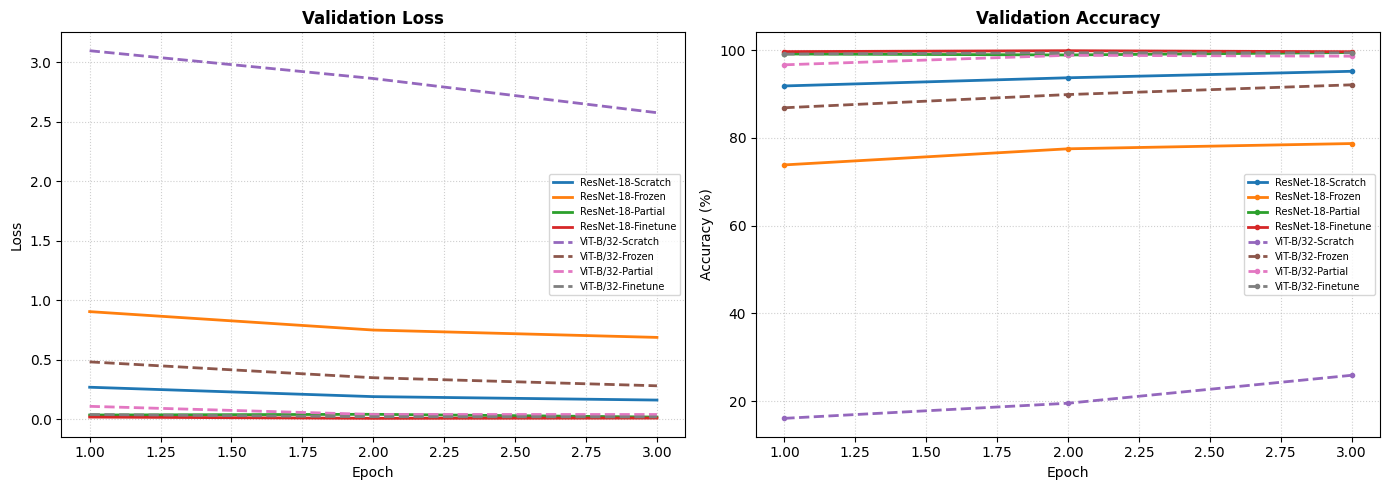

In [12]:
df_summary = pd.DataFrame(summary_results)
display(df_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
styles = {"cnn": "-", "vit": "--"}
for arch, mode, display_name in runs:
    h = history[display_name]
    axes[0].plot(range(1, EPOCHS + 1), h["val_loss"], styles[arch], linewidth=2, label=display_name)
    axes[1].plot(range(1, EPOCHS + 1), [a * 100 for a in h["val_acc"]], styles[arch], marker="o", markersize=3, linewidth=2, label=display_name)

axes[0].set_title("Validation Loss", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=7)
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].set_title("Validation Accuracy", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(fontsize=7)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "a1_learning_curves_gtsrb.png"), dpi=150)
plt.show()

## 6. So sánh Accuracy / Tham số Trainable & Ma trận nhầm lẫn

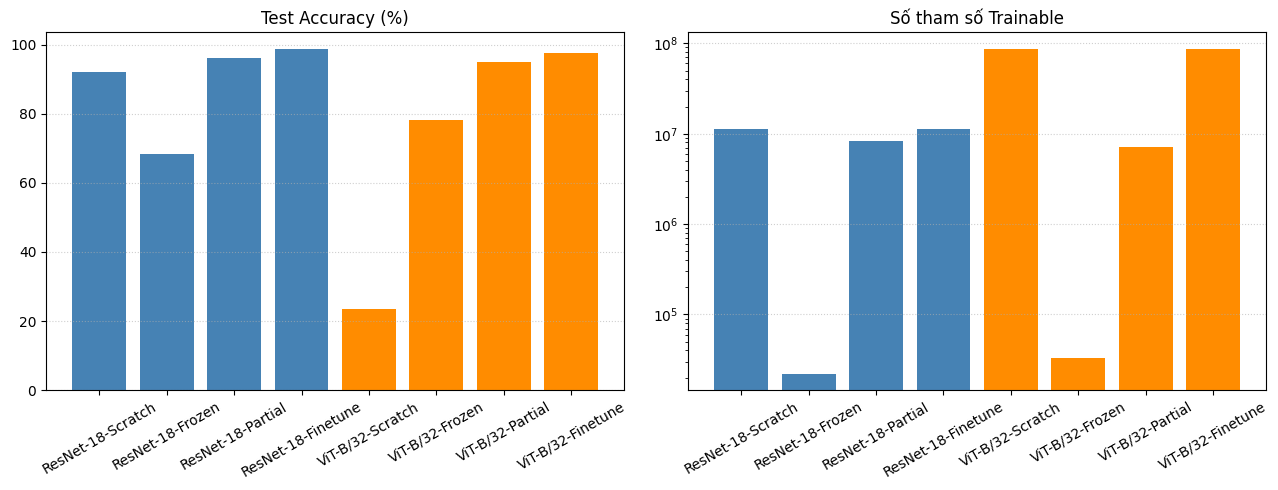

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
names = df_summary["Model"].tolist()
colors = ["steelblue" if a == "ResNet-18" else "darkorange" for a in df_summary["Arch"]]

axes[0].bar(names, df_summary["Test Acc (%)"], color=colors)
axes[0].set_title("Test Accuracy (%)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(True, axis="y", linestyle=":", alpha=0.6)

axes[1].bar(names, df_summary["Trainable Params"], color=colors)
axes[1].set_title("Số tham số Trainable")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_yscale("log")
axes[1].grid(True, axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "a1_summary_bars_gtsrb.png"), dpi=150)
plt.show()

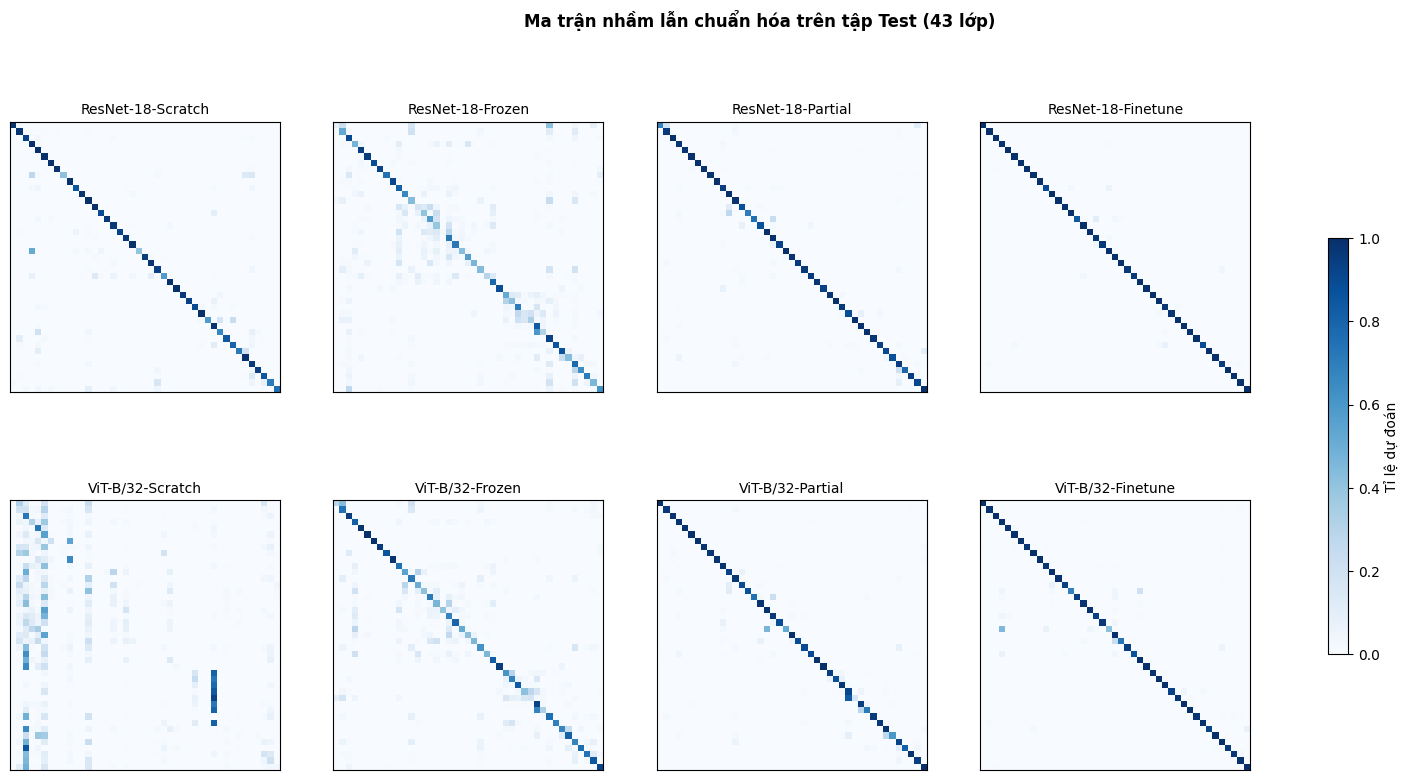

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, (arch, mode, display_name) in zip(axes.flat, runs):
    preds, labels = test_predictions[display_name]["preds"], test_predictions[display_name]["labels"]
    cm = confusion_matrix(labels, preds, labels=range(NUM_CLASSES), normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(display_name, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Ma trận nhầm lẫn chuẩn hóa trên tập Test (43 lớp)", fontweight="bold")
fig.colorbar(im, ax=axes, shrink=0.6, label="Tỉ lệ dự đoán")
plt.savefig(os.path.join(OUTPUT_DIR, "a1_confusion_matrices_gtsrb.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Lưu Kết quả

In [15]:
config_a1 = {
    "dataset": "GTSRB",
    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "val_ratio": VAL_RATIO,
    "epochs": EPOCHS,
    "optimizer": "Adam",
    "lr_by_mode": LR_BY_MODE,
    "weight_decay": 1e-4,
    "architectures": {"cnn": "resnet18", "vit": "vit_b_32"},
    "modes": ["scratch", "frozen", "partial", "finetune"],
    "device": str(device)
}
with open(os.path.join(OUTPUT_DIR, "config_a1_2.json"), "w", encoding="utf-8") as f:
    json.dump(config_a1, f, indent=4, ensure_ascii=False)

with open(os.path.join(OUTPUT_DIR, "training_log_a1_2.json"), "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

df_summary.to_csv(os.path.join(OUTPUT_DIR, "summary_results_a1_2.csv"), index=False)
print("Đã lưu thành công config_a1_2.json, training_log_a1_2.json và summary_results_a1_2.csv!")

Đã lưu thành công config_a1_2.json, training_log_a1_2.json và summary_results_a1_2.csv!


## 8. Nhận xét và Đánh giá Kết quả

Dựa trên kết quả huấn luyện (chỉ với 3 epochs) và đánh giá trên tập Test, ta có thể rút ra một số nhận xét quan trọng sau:

1. **Khả năng học từ đầu (Training from Scratch):**
   - **ResNet-18 (CNN):** Đạt kết quả khá tốt (~91.96%) ngay cả khi train từ đầu. Điều này là nhờ CNN có sẵn các thiên kiến quy nạp (inductive bias) như tính bất biến dịch chuyển (translation invariance) và tính cục bộ, giúp nó học đặc trưng ảnh rất nhanh trên các tập dữ liệu vừa và nhỏ như GTSRB.
   - **ViT-B/32 (Transformer):** Thất bại hoàn toàn khi train từ scratch (chỉ đạt ~23.36%). Vision Transformer không có sẵn inductive bias như CNN nên nó vô cùng "đói dữ liệu" (data-hungry). Nó cần lượng dữ liệu khổng lồ (như ImageNet) và số epochs rất dài để tự học cách hiểu hình ảnh. Với 3 epochs trên tập dữ liệu nhỏ, ViT không thể hội tụ.

2. **Sự hiệu quả của Pre-trained weights (Finetune & Partial):**
   - **Finetune (Huấn luyện lại toàn bộ):** Là phương pháp cho kết quả tốt nhất ở cả 2 kiến trúc (ResNet-18: 98.64%, ViT-B/32: 97.54%). Việc khởi tạo bằng tạ (weights) từ ImageNet và điều chỉnh cho tập GTSRB giúp mô hình hội tụ cực nhanh và chính xác.
   - **Partial (Chỉ mở khóa các layer cuối):** Giữ được độ chính xác rất cao (ResNet: ~96.2%, ViT: ~94.9%) trong khi giảm được số lượng tham số cần cập nhật, tiết kiệm bộ nhớ tính toán gradient.

3. **Đóng băng trích xuất đặc trưng (Frozen):**
   - Khi đóng băng toàn bộ backbone, **ViT (78.07%) lại vượt trội hơn ResNet-18 (68.43%)**. Điều này ngụ ý rằng các đặc trưng tổng quát (global features) trích xuất bởi Transformer từ ImageNet có khả năng tổng quát hóa (generalization) sang các miền dữ liệu mới tốt hơn so với các đặc trưng cục bộ của CNN.

4. **Độ phức tạp và Thời gian huấn luyện:**
   - **ViT-B/32** nặng hơn đáng kể (~87.5 triệu tham số) so với **ResNet-18** (~11.2 triệu tham số).
   - Hậu quả là thời gian huấn luyện ViT tốn gấp 2 đến 3 lần ResNet-18 ở các chế độ (ví dụ Finetune: ViT tốn ~510s, ResNet tốn ~174s).

**Kết luận tổng quan:**
Cho bài toán nhận diện biển báo giao thông trên tập GTSRB, **ResNet-18 (đặc biệt là chế độ Finetune) là sự lựa chọn tối ưu nhất** vì nó cho độ chính xác cao nhất (98.64%), kích thước mô hình nhẹ, và thời gian huấn luyện/suy luận nhanh chóng. ViT-B/32 chỉ thực sự mạnh khi có Pretrained weights, nhưng chi phí tính toán là quá đắt đỏ so với mức tăng hiệu năng đem lại trong bài toán quy mô này.